# QR and Bar Code Scanner: when does decoding fail, and is a QR code a password?

**The question:** a QR code is a picture of text, and a few lines of OpenCV can read it from a photo. The legacy notebook did exactly that for a door-pass demo: read a QR code, look the name up in a list, and say "Authorized". It worked on nine tidy sample images. *But how well does it work on a blurry, tilted, noisy photo, which decoder should you use, does shrinking the image first matter, and is "the name is on the list" a safe way to let people in?* Every code in this notebook is **generated**, so we always know the right answer.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: four decoders and a scene generator
4. Hypotheses and why we chose each test
5. H1: what breaks QR decoding?
6. H2: which decoder is best?
7. H3: does the legacy resize hurt?
8. H4: bar codes
9. H5: is a QR code a password?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab CV/qr-barcode-scanner/qr_barcode_scanner.ipynb`, or *Run All* in any Jupyter. Nothing is downloaded and no camera is needed; it takes about 5 minutes on a CPU.

## 1. 💡 The simple analogy

Imagine a **crossword grid of black and white squares** that a machine has to read from across a room.

- If the squares are **big and sharp**, easy. If they are **tiny** (2 or 3 pixels each) or **smeared** (blur), neighbouring squares merge and the message is lost, however clever the reader.
- Three of the big corner "targets" tell the reader where the grid is and which way up it is, so **rotation hardly matters**. But a **steep angle** squashes the grid and moves the targets out of place.
- A **label that says "Alice"** is not a key: anyone can print their own label that says "Alice". A **signed** label includes a stamp only the issuer can make, so a copied name without a stamp is rejected.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of codes per setting and the scene size keeps the notebook reproducible and avoids "magic numbers". The legacy notebook needed `zbar`, which its author could not install on Windows; here we use OpenCV's own readers and the pip-installable `zxing-cpp`, which work everywhere.

In [1]:
import hashlib
import hmac
import zlib
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import zxingcpp
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint

OUT_DIR = Path("outputs")
SEED = 365
N_PER_LEVEL = 100  # codes per setting in the one-factor sweeps
N_HARD = 1_000  # codes in the mixed-difficulty test
SCENE_W, SCENE_H = 480, 360
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: four decoders and a scene generator

*What:* we **encode** a random badge text with OpenCV's QR encoder, **place it in a 480 x 360 photo of a textured surface**, and damage it in controlled ways: smaller modules (the little squares), blur, noise, lower contrast, a perspective tilt and rotation. The right answer is the text we encoded, so a **success** is "decoded exactly right". Four decoders try to read it: **OpenCV classic**, **OpenCV ArUco** (a newer, marker-based detector), **OpenCV WeChat** (from the contrib module, without its neural models) and **zxing-cpp** (a C++ port of the ZXing reader that handles QR codes and bar codes).

> **Problems in the legacy notebook this replaces:** it depended on `pyzbar`/`zbarlight` and Colab's `cv2_imshow` (the author could not make it run on Windows); its `read_img` resize passed `(height, width)` to `cv2.resize`, which expects `(width, height)`, so every image came out with its **proportions flipped**; it split each payload with `myData.split('://')[1]`, which **crashes** on any QR code that does not contain `://`; and it granted access to anyone whose QR code **contained a name on a list**. It was tested on nine images.

In [2]:
ENCODER = cv2.QRCodeEncoder.create()
WECHAT = cv2.wechat_qrcode_WeChatQRCode()
CLASSIC = cv2.QRCodeDetector()
ARUCO = cv2.QRCodeDetectorAruco()
NAMES = [
    "Alice Morgan",
    "Bilal Chowdhury",
    "Chen Wei",
    "Dana Okafor",
    "Elena Petrova",
    "Farid Haddad",
    "Grace Liu",
    "Hiro Tanaka",
    "Ines Duarte",
    "Jonas Berg",
]


def random_payload(gen: np.random.Generator) -> str:
    """A random badge payload such as ``badge://Chen Wei-48213``."""
    return f"badge://{gen.choice(NAMES)}-{int(gen.integers(10000, 99999))}"


def render_qr(payload: str, module_px: int) -> np.ndarray:
    """Draws a QR code with a 4-module quiet zone.

    Args:
        payload: The text to encode.
        module_px: Pixels per QR module (the little squares).

    Returns:
        A grey image (0 = black, 255 = white).
    """
    modules = ENCODER.encode(payload)
    big = cv2.resize(modules, None, fx=module_px, fy=module_px, interpolation=cv2.INTER_NEAREST)
    pad = 4 * module_px
    return cv2.copyMakeBorder(big, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=255)


def make_scene(
    gen: np.random.Generator,
    payload: str,
    module_px: float = 5,
    rotation: float = 0,
    blur: float = 0.5,
    noise: float = 5,
    contrast: float = 1.0,
    tilt: float = 0.0,
) -> np.ndarray:
    """Photographs a QR code lying on a textured surface, with controlled damage.

    Args:
        gen: Random number generator.
        payload: The text in the code.
        module_px: Pixels per QR module in the scene.
        rotation: Rotation in degrees.
        blur: Gaussian blur sigma in pixels.
        noise: Sensor noise (standard deviation in grey levels).
        contrast: 1 = full black-and-white; smaller values squeeze towards grey.
        tilt: Perspective tilt (0 = facing the camera, 0.4 = steep).

    Returns:
        A BGR scene of shape (SCENE_H, SCENE_W, 3).
    """
    code_img = render_qr(payload, max(1, int(round(module_px)))).astype(np.float32)
    if int(round(module_px)) != module_px:
        scale = module_px / int(round(module_px))
        code_img = cv2.resize(code_img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    code_img = 128 + contrast * (code_img - 128)
    scene = (
        np.full((SCENE_H, SCENE_W), 140, np.float32)
        + cv2.GaussianBlur(gen.normal(0, 25, (SCENE_H, SCENE_W)).astype(np.float32), (0, 0), 9) * 2
    )
    h, w = code_img.shape
    centre = np.array([SCENE_W / 2 + gen.uniform(-30, 30), SCENE_H / 2 + gen.uniform(-20, 20)])
    corners = np.array([[-w, -h], [w, -h], [w, h], [-w, h]], np.float32) / 2
    corners[:2, 0] *= 1 - tilt
    corners[:2, 1] *= 1 - tilt * 0.3
    angle = np.deg2rad(rotation)
    rot = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]], np.float32)
    quad = (corners @ rot.T + centre).astype(np.float32)
    matrix = cv2.getPerspectiveTransform(np.float32([[0, 0], [w, 0], [w, h], [0, h]]), quad)
    warped = cv2.warpPerspective(
        code_img, matrix, (SCENE_W, SCENE_H), flags=cv2.INTER_LINEAR, borderValue=-1
    )
    mask = cv2.warpPerspective(np.full((h, w), 255, np.uint8), matrix, (SCENE_W, SCENE_H)) > 0
    scene = np.where(mask, warped, scene)
    if blur > 0:
        scene = cv2.GaussianBlur(scene, (0, 0), blur)
    scene = scene + gen.normal(0, noise, scene.shape)
    return cv2.cvtColor(scene.clip(0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)


def read_classic(img: np.ndarray) -> str:
    """OpenCV's original QR detector."""
    return CLASSIC.detectAndDecode(img)[0]


def read_aruco(img: np.ndarray) -> str:
    """OpenCV's newer, ArUco-based QR detector."""
    return ARUCO.detectAndDecode(img)[0]


def read_wechat(img: np.ndarray) -> str:
    """OpenCV's WeChat QR detector (no neural models loaded)."""
    result = WECHAT.detectAndDecode(img)[0]
    return result[0] if result else ""


def read_zxing(img: np.ndarray) -> str:
    """The zxing-cpp reader (handles QR codes and bar codes)."""
    found = zxingcpp.read_barcodes(img)
    return found[0].text if found else ""


DECODERS = {
    "OpenCV classic": read_classic,
    "OpenCV ArUco": read_aruco,
    "OpenCV WeChat": read_wechat,
    "zxing-cpp": read_zxing,
}
gen = np.random.default_rng(SEED)
clean = [(p := random_payload(gen), make_scene(gen, p, 6, 0, 0.3, 2)) for _ in range(200)]
clean_rate = {name: np.mean([fn(img) == p for p, img in clean]) for name, fn in DECODERS.items()}
print(
    f"Scenes are {SCENE_W} x {SCENE_H}; a code of module size 5 covers about "
    f"{(29 + 8) * 5} pixels across"
)
print("Decode rate on 200 clean, upright codes (module 6 px, hardly any blur or noise):")
for name, rate in clean_rate.items():
    print(f"  {name}: {rate:.1%}")

Scenes are 480 x 360; a code of module size 5 covers about 185 pixels across
Decode rate on 200 clean, upright codes (module 6 px, hardly any blur or noise):
  OpenCV classic: 97.0%
  OpenCV ArUco: 99.5%
  OpenCV WeChat: 100.0%
  zxing-cpp: 100.0%


**How to read this:**

- **A code of module size 5 covers about 185 pixels across** in a 480 x 360 scene, which is about 40% of the width.
- **On 200 clean, upright codes (6 px modules, almost no blur or noise), the decoders read 97.0% (OpenCV classic), 99.5% (ArUco), 100% (WeChat) and 100% (zxing-cpp).** The classic reader already drops 3 in 100 codes on this easy set, which is the first hint that "it works on my samples" is not enough.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does decoding degrade as the code is made smaller, blurrier, noisier, flatter or more tilted? | Success is the same at every level | It falls | Success rate with Wilson intervals at 5 levels of each of 6 factors, 100 codes per level |
| H2 | Do the decoders differ when damage is mixed? | Same success rate | Differs | 1,000 codes with random mixed damage; exact McNemar tests against the classic reader |
| H3 | Does the legacy resize (proportions flipped) hurt decoding? | Same success with the legacy and a proper resize | Legacy is worse | 300 paired scenes, exact McNemar test |
| H4 | How robust is bar-code reading? | n/a (estimation) | n/a | EAN-13 success rate versus bar width, blur and rotation |
| H5 | Is a name in a QR code a safe credential? | Forged badges are rejected | They are accepted | 1,000 forged badges against the legacy rule and a signed one |

*Why these tests?* Each code is decoded or not, so rates have **Wilson intervals**, and two decoders on the same codes are compared with the **exact McNemar test** (it uses only the codes where they disagree). Because we generate the codes, the truth is known exactly, so there is no labelling noise.

## 5. H1: what breaks QR decoding?

*What:* start from a comfortable baseline (5 px modules, blur 0.5, noise 5, full contrast, facing the camera, upright) and change **one factor at a time** over five levels, with 100 fresh codes per level and all four decoders. We plot the success rate with a 95% Wilson band. *Why:* real photos mix many problems, so we first need to know which ones matter on their own.

In [3]:
BASE = {"module_px": 5, "rotation": 0, "blur": 0.5, "noise": 5, "contrast": 1.0, "tilt": 0.0}
SWEEPS = {
    "module_px": [2, 3, 4, 5, 6],
    "blur": [0.5, 1.5, 2.5, 3.5, 4.5],
    "noise": [5, 20, 40, 60, 90],
    "contrast": [1.0, 0.5, 0.3, 0.2, 0.12],
    "tilt": [0.0, 0.15, 0.3, 0.45, 0.6],
    "rotation": [0, 20, 45, 70, 90],
}
LABELS = {
    "module_px": "Pixels per QR module",
    "blur": "Blur (pixels)",
    "noise": "Noise (grey levels)",
    "contrast": "Contrast (1 = full)",
    "tilt": "Perspective tilt",
    "rotation": "Rotation (degrees)",
}


def wilson(hits: int, total: int) -> tuple[float, float, float]:
    """Share with a 95% Wilson interval."""
    low, high = proportion_confint(hits, total, method="wilson")
    return hits / total, low, high


rows = []
for factor, levels in SWEEPS.items():
    for level in levels:
        setting = {**BASE, factor: level}
        gen = np.random.default_rng(SEED + zlib.crc32(f"{factor}-{level}".encode()) % 10_000)
        batch = [
            (p := random_payload(gen), make_scene(gen, p, **setting)) for _ in range(N_PER_LEVEL)
        ]
        for name, fn in DECODERS.items():
            hits = sum(fn(img) == p for p, img in batch)
            share, low, high = wilson(hits, N_PER_LEVEL)
            rows.append(
                {
                    "factor": factor,
                    "level": level,
                    "decoder": name,
                    "rate": share,
                    "ci_low": low,
                    "ci_high": high,
                }
            )
sweep = pd.DataFrame(rows)
for factor in SWEEPS:
    tab = sweep[sweep["factor"] == factor].pivot(index="level", columns="decoder", values="rate")
    print(f"\n{LABELS[factor]}: share of {N_PER_LEVEL} codes decoded correctly")
    print((tab[list(DECODERS)] * 100).round(0).astype(int).to_string())


Pixels per QR module: share of 100 codes decoded correctly
decoder  OpenCV classic  OpenCV ArUco  OpenCV WeChat  zxing-cpp
level                                                          
2.0                   1            38             99         88
3.0                  50            70            100        100
4.0                  95            83            100        100
5.0                  98            96            100        100
6.0                  98            98            100        100

Blur (pixels): share of 100 codes decoded correctly
decoder  OpenCV classic  OpenCV ArUco  OpenCV WeChat  zxing-cpp
level                                                          
0.5                  97            94            100        100
1.5                  88            38            100        100
2.5                   0             0             75         36
3.5                   0             0              0          0
4.5                   0             0              0   

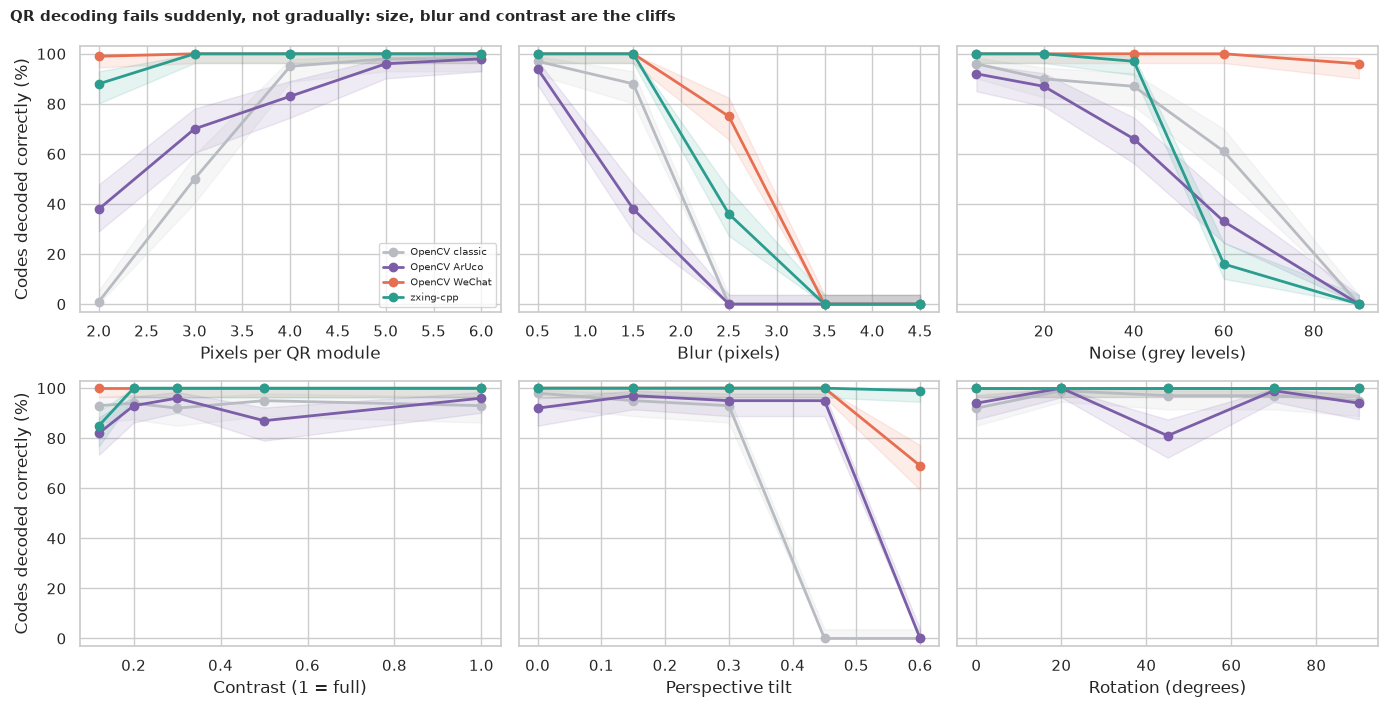

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharey=True)
for ax, factor in zip(axes.ravel(), SWEEPS, strict=True):
    for name, color in zip(DECODERS, [GREY, PURPLE, ORANGE, TEAL], strict=True):
        sub = sweep[(sweep["factor"] == factor) & (sweep["decoder"] == name)]
        ax.plot(sub["level"], sub["rate"] * 100, marker="o", color=color, lw=2, label=name)
        ax.fill_between(
            sub["level"], sub["ci_low"] * 100, sub["ci_high"] * 100, color=color, alpha=0.12
        )
    ax.set_xlabel(LABELS[factor])
    ax.set_ylim(-3, 103)
axes[0, 0].set_ylabel("Codes decoded correctly (%)")
axes[1, 0].set_ylabel("Codes decoded correctly (%)")
axes[0, 0].legend(fontsize=7, loc="lower right")
fig.suptitle(
    "QR decoding fails suddenly, not gradually: size, blur and contrast are the cliffs",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_sweeps.png", dpi=150)
plt.show()

**How to read this:**

- **Failure is a cliff, not a slope.** Size, blur and noise take every decoder from near-perfect to zero within a step or two.
- **Size:** at **2 px per module** the classic reader gets **1%**, ArUco **38%**, zxing **88%**, WeChat **99%**; at **4 px** classic reaches **95%** and from **5 px** everyone is at 96% or better.
- **Blur is the most dangerous:** at a blur of **1.5 px** classic still reads **88%**, ArUco only **38%**, WeChat and zxing **100%**. At **2.5 px** it is **0%, 0%, 75% (WeChat) and 36% (zxing)**, and at **3.5 px and above nobody reads anything**. A smeared picture has simply lost the information.
- **Noise:** at 60 grey levels of noise WeChat still reads **100%** while zxing falls to **16%**, ArUco to **33%** and classic to **61%**; at 90 only WeChat survives (**96%**).
- **Contrast is a small problem:** even at 0.12 of full contrast, all four read 82% to 100%. **Rotation hardly matters** either (every decoder at 81% or better, up to 90 degrees), which is by design.
- **Perspective tilt breaks the older readers:** at a tilt of 0.45 the classic reader falls to **0%** while ArUco, WeChat and zxing read 95% to 100%; at 0.6 only zxing (**99%**) and WeChat (**69%**) are left.
- **We reject H₀** for size, blur, noise and tilt; contrast and rotation are not the problem.

## 6. H2: which decoder is best?

*What:* 1,000 codes where every factor is damaged at random at once: module size 3 to 6 px, **any** rotation, blur 0.3 to 1.8, noise 3 to 40, contrast 0.3 to 1 and tilt up to 0.4. Each decoder reads all 1,000 and we compare each with the classic reader on the same codes using the exact McNemar test. *Why:* a single sweep is tidy but real photos are messy, and the decoder that is best at one thing may be worst at another. (We first tried a harsher mix, with blur up to 3 pixels: it was unreadable for every decoder, so it taught nothing about the differences.)

In [5]:
gen = np.random.default_rng(SEED + 7)
hard = []
for _ in range(N_HARD):
    p = random_payload(gen)
    scene = make_scene(
        gen,
        p,
        module_px=float(gen.uniform(3, 6)),
        rotation=float(gen.uniform(0, 360)),
        blur=float(gen.uniform(0.3, 1.8)),
        noise=float(gen.uniform(3, 40)),
        contrast=float(gen.uniform(0.3, 1.0)),
        tilt=float(gen.uniform(0, 0.4)),
    )
    hard.append((p, scene))
results = {name: np.array([fn(img) == p for p, img in hard]) for name, fn in DECODERS.items()}
rows = []
for name, ok in results.items():
    share, low, high = wilson(int(ok.sum()), N_HARD)
    rows.append({"decoder": name, "decoded": share, "ci_low": low, "ci_high": high})
hard_table = pd.DataFrame(rows).set_index("decoder")
print(
    f"{N_HARD:,} codes with mixed random damage (size 3 to 6 px, any rotation, blur 0.3 to 1.8, "
    "noise 3 to 40, contrast 0.3 to 1, tilt up to 0.4):"
)
print((hard_table * 100).round(1).to_string())
base = results["OpenCV classic"]
for name in ("OpenCV ArUco", "OpenCV WeChat", "zxing-cpp"):
    ok = results[name]
    mc = mcnemar(
        [
            [int((ok & base).sum()), int((ok & ~base).sum())],
            [int((~ok & base).sum()), int((~ok & ~base).sum())],
        ],
        exact=True,
    )
    print(
        f"{name} vs classic: reads {int((ok & ~base).sum())} codes the classic reader misses, "
        f"misses {int((~ok & base).sum())} it reads; exact McNemar p = {fmt_p(mc.pvalue)}"
    )
any_ok = np.any(list(results.values()), axis=0)
print(
    f"\nCodes read by at least one decoder: {any_ok.mean():.1%}; "
    f"read by none: {(~any_ok).mean():.1%}"
)

1,000 codes with mixed random damage (size 3 to 6 px, any rotation, blur 0.3 to 1.8, noise 3 to 40, contrast 0.3 to 1, tilt up to 0.4):
                decoded  ci_low  ci_high
decoder                                 
OpenCV classic     27.2    24.5     30.0
OpenCV ArUco       27.4    24.7     30.2
OpenCV WeChat      48.7    45.6     51.8
zxing-cpp          43.2    40.2     46.3
OpenCV ArUco vs classic: reads 105 codes the classic reader misses, misses 103 it reads; exact McNemar p = 9.4e-01
OpenCV WeChat vs classic: reads 240 codes the classic reader misses, misses 25 it reads; exact McNemar p = 2.9e-45
zxing-cpp vs classic: reads 191 codes the classic reader misses, misses 31 it reads; exact McNemar p = 2.6e-29

Codes read by at least one decoder: 55.8%; read by none: 44.2%


**How to read this:**

- **Mixed damage is hard for all of them:** decoded correctly **27.2%** (OpenCV classic, 95% CI 24.5% to 30.0%), **27.4%** (ArUco), **48.7%** (WeChat, 45.6% to 51.8%) and **43.2%** (zxing-cpp, 40.2% to 46.3%).
- **ArUco is no better than classic:** it reads 105 codes classic misses and misses 103 that classic reads (McNemar p = 0.94). The "newer" detector is simply different, not better.
- **WeChat and zxing-cpp are clearly better:** WeChat reads **240** codes classic misses and misses **25** (p = 3e-45); zxing reads **191** and misses **31** (p = 3e-29).
- **No decoder is good enough alone:** only **55.8%** of the codes are read by at least one decoder, and **44.2%** by none. A decoder is a tool, and the photo's quality sets the ceiling.

## 7. H3: does the legacy resize hurt?

*What:* the legacy `read_img` made every image 200 pixels wide, but passed the arguments in the wrong order, so a 960 x 720 photo became **200 x 150 in the wrong orientation** (squashed horizontally by almost 2 times). We take 300 scenes (a 5 to 6 px code in a 960 x 720 photo), decode them three ways, with **no resize**, with the **legacy resize** and with a **proper resize** to 200 pixels wide, and compare with the OpenCV classic reader (the one the legacy approach is closest to) and zxing-cpp, using the exact McNemar test. *Why:* a one-character mix-up in an argument order can quietly break a pipeline.

In [6]:
def legacy_resize(img: np.ndarray, width: int = 200) -> np.ndarray:
    """The legacy script's ``read_img`` resize, bug included.

    It computes a height that keeps the aspect ratio but then passes ``(height, width)`` to
    ``cv2.resize``, which expects ``(width, height)``, so the picture comes out with its
    proportions flipped.

    Args:
        img: The camera image.
        width: Intended output width.

    Returns:
        The resized image.
    """
    h, w = img.shape[:2]
    height = int(h * width / float(w))
    return cv2.resize(img, (height, width))


def proper_resize(img: np.ndarray, width: int = 200) -> np.ndarray:
    """Resizes to a given width, keeping the proportions."""
    h, w = img.shape[:2]
    return cv2.resize(img, (width, int(h * width / w)), interpolation=cv2.INTER_AREA)


gen = np.random.default_rng(SEED + 11)
resize_scenes = []
for _ in range(300):
    p = random_payload(gen)
    big = cv2.resize(make_scene(gen, p, module_px=6, blur=0.8, noise=6), (960, 720))
    resize_scenes.append((p, big))
treatments = {
    "no resize": lambda im: im,
    "legacy resize (flipped proportions)": legacy_resize,
    "proper resize to 200 px wide": proper_resize,
}
rows, outcomes = [], {}
for reader_name in ("OpenCV classic", "zxing-cpp"):
    reader = DECODERS[reader_name]
    for tname, fn in treatments.items():
        ok = np.array([reader(fn(img)) == p for p, img in resize_scenes])
        outcomes[(reader_name, tname)] = ok
        share, low, high = wilson(int(ok.sum()), len(ok))
        shape = fn(resize_scenes[0][1]).shape[:2]
        rows.append(
            {
                "reader": reader_name,
                "treatment": tname,
                "image shape (h, w)": shape,
                "decoded": share,
                "ci_low": low,
                "ci_high": high,
            }
        )
resize_table = pd.DataFrame(rows).set_index(["reader", "treatment"])
print(resize_table.round(3).to_string())
for reader_name in ("OpenCV classic", "zxing-cpp"):
    legacy_ok = outcomes[(reader_name, "legacy resize (flipped proportions)")]
    proper_ok = outcomes[(reader_name, "proper resize to 200 px wide")]
    mc = mcnemar(
        [
            [int((legacy_ok & proper_ok).sum()), int((legacy_ok & ~proper_ok).sum())],
            [int((~legacy_ok & proper_ok).sum()), int((~legacy_ok & ~proper_ok).sum())],
        ],
        exact=True,
    )
    print(
        f"{reader_name}: proper resize reads {int((~legacy_ok & proper_ok).sum())} codes that "
        f"the legacy resize loses, the legacy resize reads {int((legacy_ok & ~proper_ok).sum())} "
        f"that proper loses; exact McNemar p = {fmt_p(mc.pvalue)}"
    )

                                                   image shape (h, w)  decoded  ci_low  ci_high
reader         treatment                                                                       
OpenCV classic no resize                                   (720, 960)    0.997   0.981    0.999
               legacy resize (flipped proportions)         (200, 150)    0.000   0.000    0.013
               proper resize to 200 px wide                (150, 200)    0.840   0.794    0.877
zxing-cpp      no resize                                   (720, 960)    1.000   0.987    1.000
               legacy resize (flipped proportions)         (200, 150)    1.000   0.987    1.000
               proper resize to 200 px wide                (150, 200)    1.000   0.987    1.000
OpenCV classic: proper resize reads 252 codes that the legacy resize loses, the legacy resize reads 0 that proper loses; exact McNemar p = 2.8e-76
zxing-cpp: proper resize reads 0 codes that the legacy resize loses, the legacy resiz

**How to read this:**

- **The legacy resize is fatal for the classic reader:** **99.7%** decoded with no resize (95% CI 98.1% to 99.9%), **0.0%** after the legacy resize (0.0% to 1.3%) and **84.0%** after a proper resize to the same width (79.4% to 87.7%). The proper resize reads **252** codes that the legacy one loses and the legacy one reads **0** that the proper one loses (McNemar p = 3e-76). **We reject H₀.**
- **zxing-cpp is immune:** **100%** in all three treatments, so the squashing makes no difference to a decoder that handles distortion. The bug only bites with some readers, which is why it can hide.
- **Shrinking itself costs something:** even the correct resize loses 16 points for the classic reader (99.7% to 84.0%), because the code ends up only about 2 to 3 pixels per module. Resizing is a trade that should be tested, not assumed.

## 8. H4: bar codes

*What:* the legacy `pyzbar` library also read bar codes, so we test the common **EAN-13** product code. We generate random 12-digit numbers, add the correct check digit, draw the bars with standard proportions (a bar code is about 0.6 times as tall as wide) and read them with zxing-cpp, counting a success only when all 13 digits are right. We vary the **width of each bar module** (1 to 4 px), the **blur** and the **rotation**, 100 codes per level. (OpenCV's own bar-code detector found nothing in these clean synthetic bars, which are drawn cleanly rather than photographed, so it is not compared.)

In [7]:
L_CODES = [
    "0001101",
    "0011001",
    "0010011",
    "0111101",
    "0100011",
    "0110001",
    "0101111",
    "0111011",
    "0110111",
    "0001011",
]
G_CODES = [
    "0100111",
    "0110011",
    "0011011",
    "0100001",
    "0011101",
    "0111001",
    "0000101",
    "0010001",
    "0001001",
    "0010111",
]
R_CODES = [
    "1110010",
    "1100110",
    "1101100",
    "1000010",
    "1011100",
    "1001110",
    "1010000",
    "1000100",
    "1001000",
    "1110100",
]
PARITY = [
    "LLLLLL",
    "LLGLGG",
    "LLGGLG",
    "LLGGGL",
    "LGLLGG",
    "LGGLLG",
    "LGGGLL",
    "LGLGLG",
    "LGLGGL",
    "LGGLGL",
]


def ean13(first_twelve: str) -> tuple[str, str]:
    """Encodes 12 digits as an EAN-13 bar code, adding the check digit.

    Args:
        first_twelve: Twelve digits.

    Returns:
        The full 13-digit number and the 95-module bar pattern ("1" = black).
    """
    d = [int(c) for c in first_twelve]
    check = (10 - (sum(d[0::2]) + 3 * sum(d[1::2])) % 10) % 10
    full = first_twelve + str(check)
    bits = "101"
    for i, c in enumerate(full[1:7]):
        bits += (L_CODES if PARITY[int(full[0])][i] == "L" else G_CODES)[int(c)]
    bits += "01010" + "".join(R_CODES[int(c)] for c in full[7:]) + "101"
    return full, bits


def make_bar_scene(
    gen: np.random.Generator, bits: str, module_px: int, rotation: float, blur: float
) -> np.ndarray:
    """Photographs a bar code on a plain surface with controlled damage."""
    row = np.array([0 if b == "1" else 255 for b in bits], np.uint8).repeat(module_px)
    bar_height = int(0.6 * len(row))  # a real EAN-13 is about 0.6 times as tall as it is wide
    bars = cv2.copyMakeBorder(
        np.tile(row, (bar_height, 1)),
        20,
        20,
        12 * module_px,
        12 * module_px,
        cv2.BORDER_CONSTANT,
        value=255,
    )
    canvas = np.full((SCENE_H, SCENE_W), 150, np.uint8)
    h, w = bars.shape
    y0, x0 = (SCENE_H - h) // 2, (SCENE_W - w) // 2
    canvas[y0 : y0 + h, x0 : x0 + w] = bars
    matrix = cv2.getRotationMatrix2D((SCENE_W / 2, SCENE_H / 2), rotation, 1.0)
    canvas = cv2.warpAffine(canvas, matrix, (SCENE_W, SCENE_H), borderValue=150)
    canvas = canvas.astype(np.float32)
    if blur > 0:
        canvas = cv2.GaussianBlur(canvas, (0, 0), blur)
    canvas += gen.normal(0, 4, canvas.shape)
    return cv2.cvtColor(canvas.clip(0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)


BAR_SWEEPS = {
    "module_px": [1, 2, 3, 4],
    "blur": [0.0, 1.0, 2.0, 3.0, 4.0],
    "rotation": [0, 15, 45, 90],
}
rows = []
for factor, levels in BAR_SWEEPS.items():
    for level in levels:
        setting = {"module_px": 3, "rotation": 0, "blur": 0.0, **{factor: level}}
        gen = np.random.default_rng(
            SEED + 100 + zlib.crc32(f"bar-{factor}-{level}".encode()) % 10_000
        )
        hits = 0
        for _ in range(N_PER_LEVEL):
            full, bits = ean13("".join(str(int(x)) for x in gen.integers(0, 10, 12)))
            img = make_bar_scene(gen, bits, **setting)
            found = zxingcpp.read_barcodes(img)
            hits += bool(found and found[0].text == full)
        share, low, high = wilson(hits, N_PER_LEVEL)
        rows.append(
            {"factor": factor, "level": level, "rate": share, "ci_low": low, "ci_high": high}
        )
bar = pd.DataFrame(rows)
for factor in BAR_SWEEPS:
    sub = bar[bar["factor"] == factor]
    print(
        f"{factor}: " + ", ".join(f"{r.level:g} -> {r.rate * 100:.0f}%" for r in sub.itertuples())
    )

module_px: 1 -> 100%, 2 -> 100%, 3 -> 100%, 4 -> 100%
blur: 0 -> 100%, 1 -> 100%, 2 -> 0%, 3 -> 0%, 4 -> 0%
rotation: 0 -> 100%, 15 -> 100%, 45 -> 0%, 90 -> 100%


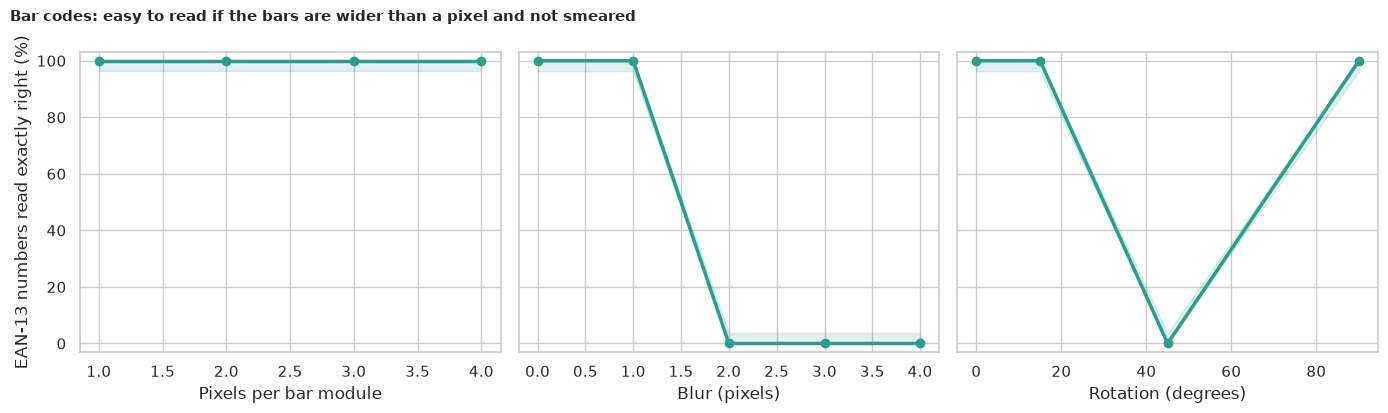

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (factor, label) in zip(
    axes,
    [
        ("module_px", "Pixels per bar module"),
        ("blur", "Blur (pixels)"),
        ("rotation", "Rotation (degrees)"),
    ],
    strict=True,
):
    sub = bar[bar["factor"] == factor]
    ax.plot(sub["level"], sub["rate"] * 100, marker="o", color=TEAL, lw=2.5)
    ax.fill_between(sub["level"], sub["ci_low"] * 100, sub["ci_high"] * 100, color=TEAL, alpha=0.15)
    ax.set_xlabel(label)
    ax.set_ylim(-3, 103)
axes[0].set_ylabel("EAN-13 numbers read exactly right (%)")
fig.suptitle(
    "Bar codes: easy to read if the bars are wider than a pixel and not smeared",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_barcodes.png", dpi=150)
plt.show()

**How to read this:**

- **Bar width is not a problem:** even **1 pixel** per module is read **100%** of the time (and 2, 3 and 4 px as well). Bar codes are far more tolerant of small size than QR codes.
- **Blur is again the cliff:** **100%** at blur 0 and 1 (with 3 px bars), then **0%** at blur 2 and above: once the bars are smeared into each other the number is lost.
- **Rotation works up to a point:** **100%** at 0, 15 and 90 degrees but **0%** at 45 degrees. A bar code is read along a line, and a diagonal scan across the bars does not work for this reader; it handles horizontal and vertical codes and mild tilt.
- **We reject H₀** for blur and for diagonal rotation only. A bar code that is sharp and roughly horizontal or vertical is read perfectly.

## 9. H5: is a QR code a password?

*What:* the legacy "door pass" accepted any QR code whose text contained a registered name. We compare two rules against **1,000 forged badges** each: (1) the **legacy rule** against a forger who only knows a registered name (for example from a name tag); (2) a **signed badge**, where the payload is `name.signature` and the signature is an HMAC (a keyed hash) of the name using a secret kept by the issuer, checked with a constant-time comparison. The forger of a signed badge has to *guess* the signature. We also see what the legacy rule does with ordinary QR codes that do not contain `://`. *Why:* a QR code is only a picture of text; it proves nothing about who made it.

In [9]:
REGISTERED = set(NAMES[:5])
SECRET = hashlib.sha256(b"a-secret-kept-on-the-server").digest()


def legacy_check(payload: str) -> str:
    """The legacy rule: split off the ``xxx://`` part and see if the name is on the list."""
    name = payload.split("://")[1]  # raises IndexError if there is no "://"
    return "Authorized" if name in REGISTERED else "Un-Authorized"


def issue_token(name: str) -> str:
    """A badge payload that carries a signature only the issuer can produce."""
    tag = hmac.new(SECRET, name.encode(), hashlib.sha256).hexdigest()[:16]
    return f"badge://{name}.{tag}"


def signed_check(payload: str) -> str:
    """Accepts a badge only if its signature matches the name (constant-time comparison)."""
    try:
        name, tag = payload.split("://", 1)[1].rsplit(".", 1)
    except (IndexError, ValueError):
        return "Un-Authorized"
    expected = hmac.new(SECRET, name.encode(), hashlib.sha256).hexdigest()[:16]
    ok = name in REGISTERED and hmac.compare_digest(tag, expected)
    return "Authorized" if ok else "Un-Authorized"


gen = np.random.default_rng(SEED + 21)
n_forged = 1_000
registered = sorted(REGISTERED)
forged_legacy = [f"badge://{gen.choice(registered)}" for _ in range(n_forged)]  # name only
forged_signed = [f"badge://{gen.choice(registered)}.{gen.bytes(8).hex()}" for _ in range(n_forged)]
legacy_accept = np.mean([legacy_check(p) == "Authorized" for p in forged_legacy])
signed_accept = np.mean([signed_check(p) == "Authorized" for p in forged_signed])
genuine = [issue_token(n) for n in registered]
genuine_accept = np.mean([signed_check(p) == "Authorized" for p in genuine])
low, high = proportion_confint(int(legacy_accept * n_forged), n_forged, method="wilson")
print(
    f"Forged badges that only know a registered name, under the legacy rule: "
    f"{legacy_accept:.1%} accepted (95% CI {low:.1%} to {high:.1%})"
)
low, high = proportion_confint(int(signed_accept * n_forged), n_forged, method="wilson")
print(
    f"Forged badges with a guessed signature, under the signed rule: {signed_accept:.1%} "
    f"accepted (95% CI {low:.1%} to {high:.1%}); genuine signed badges accepted: "
    f"{genuine_accept:.0%}"
)
messy = ["hello world", "https://example.com", "12345", "", "badge:/Alice Morgan", "badge://x"]
crashes = 0
for p in messy:
    try:
        legacy_check(p)
    except IndexError:
        crashes += 1
print(
    f"\nOf {len(messy)} ordinary QR payloads without the exact 'xxx://' format, the legacy "
    f"rule crashes on {crashes}"
)
payload_ok = zxingcpp.read_barcodes(render_qr(genuine[0], 6))[0].text == genuine[0]
print(f"A signed badge still scans like any other QR code: {payload_ok}")

Forged badges that only know a registered name, under the legacy rule: 100.0% accepted (95% CI 99.6% to 100.0%)
Forged badges with a guessed signature, under the signed rule: 0.0% accepted (95% CI 0.0% to 0.4%); genuine signed badges accepted: 100%

Of 6 ordinary QR payloads without the exact 'xxx://' format, the legacy rule crashes on 4
A signed badge still scans like any other QR code: True


**How to read this:**

- **The legacy rule accepts every forged badge:** **100.0%** (95% CI 99.6% to 100.0%). Anyone who can print a QR code that says "Alice Morgan" is "Authorized". The check proves nothing.
- **The signed rule accepts none:** a forger who guesses the signature is accepted **0.0%** of the time (95% CI 0.0% to 0.4%), while the genuine signed badges are accepted **100%** of the time. The signed badge still scans like any other QR code.
- **The legacy rule also crashes:** on 6 ordinary QR payloads ("hello world", a web address, a number, an empty code and so on), the `split('://')[1]` crashes on **4**, which anyone could use to knock the scanner over by presenting a QR code with no `://`.
- **A caution:** a signed badge can still be photographed and shown again by someone else (a **replay**). Real systems add expiry times or one-time codes; a signature stops forgery, not copying.

## 10. 🎯 Takeaways

1. **QR decoding fails like a cliff:** size (2 px modules), blur (2.5 px and above), noise and steep tilt each take a decoder from near-perfect to near-zero in a step; contrast and rotation are not the problem.
2. **Blur is the killer:** at 3.5 px blur no decoder reads anything, at 1.5 px the ArUco reader already falls to 38%.
3. **The decoder matters:** on 1,000 messily damaged codes OpenCV classic and ArUco read 27%, WeChat 49% and zxing-cpp 43% (McNemar p below 1e-28 against classic); 44% of the codes were unreadable by any of them.
4. **A swapped pair of arguments can be fatal:** the legacy resize cut the classic reader from 99.7% to 0.0% and was invisible to zxing-cpp.
5. **Bar codes are tougher than QR codes** on size (1 px bars read perfectly) and just as vulnerable to blur; they must be roughly horizontal or vertical.
6. **A QR code is not a password:** the legacy name check accepted 100% of forgeries; a signed badge accepted 0% (and replay still needs defending against).

## 11. ⚠️ Limitations

- **Synthetic photos.** Our scenes have a textured surface, blur, noise and tilt, but real photos add glare, curved labels, reflections and motion blur, which can make things worse.
- **Four decoders with default settings.** Tuned parameters, image sharpening or super-resolution (for example the WeChat detector's neural models, which we did not load) could shift every number.
- **The damage ranges are our choice.** The "mixed" test is only a mixture; its absolute rates (27% to 49%) say how hard we made it, so read it as a comparison between decoders, not a forecast.
- **One bar-code type.** We tested EAN-13 with zxing-cpp only; other symbologies and OpenCV's own detector (which found nothing in our clean synthetic bars) were not compared.
- **The signing demo is illustrative.** A real system needs key management, expiry and replay protection, which we do not build.
- **The legacy code was not run as written** (it needed `pyzbar` and Colab); its resize and its name check were re-implemented in a few lines.